# Robustness checks across the chronological folds

This notebook reviews how predictive and long-or-cash results vary across the five existing validation folds. Each fold is treated as a separate portfolio that starts and ends flat. Returns are therefore compared across folds and are not compounded together.

The folds have already informed model and strategy review, so this is a stability check rather than a new untouched final test. Transaction costs remain illustrative scenarios.

In [1]:
# Load the already-saved fold metrics and separate flat-start/flat-end returns.
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
RESULTS = ROOT / 'results'
fold_metrics = pd.read_csv(RESULTS / 'robustness_fold_metrics.csv')
backtest_folds = pd.read_csv(RESULTS / 'robustness_backtest_by_fold.csv')
stability = pd.read_csv(RESULTS / 'robustness_backtest_stability.csv')
print(f"Predictive rows: {len(fold_metrics)}; fold backtest rows: {len(backtest_folds)}")

Predictive rows: 50; fold backtest rows: 250


## Predictive performance by fold

Compare the saved fold metrics to see whether a model's results are steady or depend on a particular test period.

In [2]:
# Review the model metrics one ETF, model and fold at a time.
fold_metrics.sort_values(['ETF', 'model', 'fold'])

,ETF,fold,model,train_rows,test_rows,train_start,train_end,test_start,test_end,accuracy,balanced_accuracy,f1_up,roc_auc
0,QQQ,1,Direction persistence baseline,43169,4626,2022-03-07,2024-12-06,2024-12-09,2025-04-25,0.485733,0.485665,0.491992,NaN
5,QQQ,2,Direction persistence baseline,48939,4699,2022-03-07,2025-04-25,2025-04-28,2025-09-09,0.485848,0.485849,0.489865,NaN
10,QQQ,3,Direction persistence baseline,54758,4669,2022-03-07,2025-09-09,2025-09-10,2026-01-22,0.485115,0.485120,0.486763,NaN
15,QQQ,4,Direction persistence baseline,60544,4709,2022-03-07,2026-01-22,2026-01-23,2026-06-05,0.493098,0.493104,0.496095,NaN
20,QQQ,5,Direction persistence baseline,66366,4716,2022-03-07,2026-06-05,2026-06-08,2026-10-16,0.456743,0.456745,0.455357,NaN
1,QQQ,1,LSTM,43169,4626,2022-03-07,2024-12-06,2024-12-09,2025-04-25,0.511673,0.508786,0.584666,0.509417
6,QQQ,2,LSTM,48939,4699,2022-03-07,2025-04-25,2025-04-28,2025-09-09,0.513939,0.510348,0.604022,0.514702
11,QQQ,3,LSTM,54758,4669,2022-03-07,2025-09-09,2025-09-10,2026-01-22,0.511673,0.510074,0.595027,0.517443
16,QQQ,4,LSTM,60544,4709,2022-03-07,2026-01-22,2026-01-23,2026-06-05,0.507751,0.504229,0.614950,0.502618
21,QQQ,5,LSTM,66366,4716,2022-03-07,2026-06-05,2026-06-08,2026-10-16,0.525869,0.525711,0.600714,0.551587


## Trading results by fold

The table reports net cumulative return and drawdown for each model, fold, and per-side cost assumption. A separate fold portfolio pays to close its final position at the fold boundary.

In [3]:
# Inspect XGBoost returns at each cost rate for every separate test fold.
backtest_folds.loc[
    backtest_folds['model'].eq('XGBoost')
    & backtest_folds['cost_bps_per_side'].isin([0.0, 1.0, 2.5, 5.0, 10.0]),
    ['ETF', 'fold', 'cost_bps_per_side', 'sessions', 'net_cumulative_return',
     'maximum_drawdown', 'annualized_daily_sharpe', 'entries_per_session']
].sort_values(['ETF', 'cost_bps_per_side', 'fold'])

,ETF,fold,cost_bps_per_side,sessions,net_cumulative_return,maximum_drawdown,annualized_daily_sharpe,entries_per_session
15,QQQ,1,0.0,93,0.065127,-0.062964,1.435010,11.344086
40,QQQ,2,0.0,93,0.075726,-0.016997,3.436028,10.827957
65,QQQ,3,0.0,93,0.057410,-0.030103,2.354491,10.978495
90,QQQ,4,0.0,93,0.065060,-0.031366,3.132812,11.870968
115,QQQ,5,0.0,92,0.063125,-0.018802,2.608130,11.619565
16,QQQ,1,1.0,93,-0.137497,-0.183932,-3.178882,11.344086
41,QQQ,2,1.0,93,-0.120511,-0.124544,-6.066486,10.827957
66,QQQ,3,1.0,93,-0.137903,-0.137903,-6.050642,10.978495
91,QQQ,4,1.0,93,-0.145962,-0.146489,-7.925106,11.870968
116,QQQ,5,1.0,92,-0.141525,-0.141525,-6.508947,11.619565


## Fold-to-fold range

These summaries show the mean, median and range of each fold's net return, plus how many folds were positive. The range helps identify sensitivity to the selected evaluation period.

In [4]:
# Compare the range of fold returns without compounding different folds together.
stability.loc[
    stability['model'].eq('XGBoost')
    & stability['cost_bps_per_side'].isin([0.0, 1.0, 2.5, 5.0, 10.0]),
    ['ETF', 'cost_bps_per_side', 'folds', 'positive_return_folds',
     'mean_net_cumulative_return', 'median_net_cumulative_return',
     'minimum_net_cumulative_return', 'maximum_net_cumulative_return',
     'mean_maximum_drawdown']
].sort_values(['ETF', 'cost_bps_per_side'])

,ETF,cost_bps_per_side,folds,positive_return_folds,mean_net_cumulative_return,median_net_cumulative_return,minimum_net_cumulative_return,maximum_net_cumulative_return,mean_maximum_drawdown
20,QQQ,0.0,5,5,0.065290,0.065060,0.057410,0.075726,-0.032046
21,QQQ,1.0,5,0,-0.136680,-0.137903,-0.145962,-0.120511,-0.146879
22,QQQ,2.5,5,0,-0.370131,-0.371533,-0.386784,-0.349860,-0.371386
23,QQQ,5.0,5,0,-0.627518,-0.629229,-0.646985,-0.607122,-0.627518
24,QQQ,10.0,5,0,-0.869674,-0.871002,-0.883058,-0.856585,-0.869674
45,SPY,0.0,5,5,0.050645,0.058713,0.005763,0.090743,-0.032222
46,SPY,1.0,5,0,-0.152494,-0.140115,-0.187624,-0.121153,-0.158312
47,SPY,2.5,5,0,-0.385903,-0.381966,-0.422098,-0.353640,-0.385903
48,SPY,5.0,5,0,-0.640886,-0.643533,-0.672434,-0.612714,-0.640886
49,SPY,10.0,5,0,-0.877015,-0.873725,-0.894803,-0.861011,-0.877015


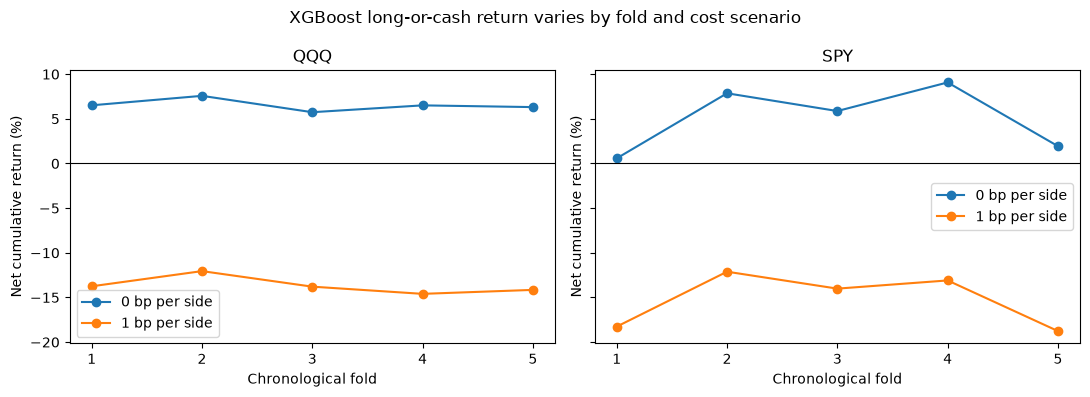

In [5]:
# Plot the two most useful cost cases to show fold-to-fold sensitivity.
plot_data = backtest_folds.loc[
    backtest_folds['model'].eq('XGBoost')
    & backtest_folds['cost_bps_per_side'].isin([0.0, 1.0])
].copy()

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for axis, ticker in zip(axes, sorted(plot_data['ETF'].unique())):
    ticker_data = plot_data.loc[plot_data['ETF'].eq(ticker)]
    for cost, group in ticker_data.groupby('cost_bps_per_side'):
        axis.plot(group['fold'], group['net_cumulative_return'] * 100,
                  marker='o', label=f'{cost:g} bp per side')
    axis.axhline(0, color='black', linewidth=0.8)
    axis.set(title=ticker, xlabel='Chronological fold', ylabel='Net cumulative return (%)')
    axis.set_xticks(sorted(ticker_data['fold'].unique()))
    axis.legend()
fig.suptitle('XGBoost long-or-cash return varies by fold and cost scenario')
fig.tight_layout()
plt.show()

## Interpretation prompts for the student

- Are model metrics similar across folds, or concentrated in one period?
- Do any of the cost assumptions produce positive returns in most folds?
- How do drawdowns and turnover change the practical interpretation?
- What limitations follow from using these same folds during model review?